# Explore share paths via overlap analysis

This script is for exploring the overlap between connectivity signatures defined by PLSes

Example data is provided in order to run the code. All original data is avaliable on the NBDC Data Hub (https://www.nbdc-datahub.org/).

Written by: Alexa Mousley (alexa.mousley@mrc-cbu.cam.ac.uk)
*October 2026*

In [ ]:
### Import packages ###

from A_config import  *                                 # Import custom paths
from A_functions import *                               # Import custom function
import os                                               # For combining paths
import numpy as np                                      # Basic requirements 
import pandas as pd                                     # Basic requirements
import seaborn as sns                                   # Plotting  
import nibabel as nib                                   # Load FreeSurfer files
from sklearn.preprocessing import StandardScaler        # Standardize data

In [ ]:
### Load data ###

# Associated data
associated_data = pd.read_csv(os.path.join(data_dir,"associated_data_example.csv"))

# Subsample associated data
subsample_associated_data = pd.read_csv(os.path.join(data_dir,"subsample_associated_data_example.csv"))

# Networks
all_connectomes =  np.load(os.path.join(data_dir, "connectomes.npz"))['connectomes']
# Pull only networks for those with matching associated data
connectomes = all_connectomes[:,:,associated_data['imaging_index'].values]
nnodes, _, nsub = connectomes.shape # Define number of nodes and number of participants

# Pull networks for genetics subsample
subsample_index = associated_data['participant_id'].isin(subsample_associated_data['participant_id']).values
# Pull only networks for those with matching genetic data
subsample_connectomes = all_connectomes[:,:,subsample_associated_data['imaging_index'].values]
_, _, subsample_nsub = subsample_connectomes.shape # Define number of participants in subsample

# Load permutation & bootstrapping data if already run (or plotting examples)
pls_x_weights = pd.read_csv(os.path.join(data_dir,"pls_x_weights_example.csv"))
pls_y_weights = pd.read_csv(os.path.join(data_dir,"pls_y_weights_example.csv"))
subsample_pls_y_weights = pd.read_csv(os.path.join(data_dir,"subsample_pls_y_weights_example.csv"))
subsample_pls_x_weights = pd.read_csv(os.path.join(data_dir,"subsample_pls_x_weights_example.csv"))

# Matrices of edges that are stable for each PLS
adversity_edge_matrix = np.load(os.path.join(data_dir, 'adversity_edge_matrix_example.npy'))
mental_health_edge_matrix = np.load(os.path.join(data_dir, 'mental_health_edge_matrix_example.npy'))
genetics_LV1_edge_matrix = np.load(os.path.join(data_dir, 'genetics_LV1_edge_matrix_example.npy'))
genetics_LV2_edge_matrix = np.load(os.path.join(data_dir, 'genetics_LV2_edge_matrix_example.npy'))

# Zero masks from vectorizing (to be used to ensure edges align)
zero_mask = np.load(os.path.join(data_dir, "zero_mask_example.npy"))
genetics_zero_mask = np.load(os.path.join(data_dir, "genetics_zero_mask_example.npy"))

# Atlas
atlas = pd.read_pickle(os.path.join(data_dir,'brainnetome.pkl'))
atlas_coords = atlas['coordinates']
region_labels = np.array(atlas['region_label'])
region_lobes = np.array(atlas['lobe'])
distances = atlas['euclidean_distance']

# Vertices and faces for plotting surfaces
lh_vertices, lh_faces = nib.freesurfer.read_geometry(os.path.join(fs_path,"lh.pial"))
rh_vertices, rh_faces = nib.freesurfer.read_geometry(os.path.join(fs_path,"rh.pial"))

# Create a dict for plotting data
plot_args = dict(atlas_coords=atlas_coords, lh_vertices=lh_vertices,region_labels=region_labels,
                 region_lobes=region_lobes,distances=distances,
                 rh_vertices=rh_vertices, save_path=save_dir)

In [3]:
### Set up data ###

# Mental health
mental_health = associated_data['mental_health_score'].values

# Adversity data
adversity_labels = ['Household_Community_Instability','Physical_Sexual_Abuse','Parental_Neglect','Financial_Difficulties']
adversity = associated_data[adversity_labels].values

# PGS
pgs_labels = subsample_associated_data.loc[:, 'CT':'VasDem'].columns.tolist()
pgs = subsample_associated_data[pgs_labels]

# Number of possible edges
n_edges = int((nnodes*(nnodes-1))/2)    

# Set  up covariates for GLMs
covs_continuous = StandardScaler().fit_transform(associated_data[['age', 'cognitive_score', 'dmri_meanmotion']].values.astype(float))
covs_categorical = associated_data[['sex', 'site', 'mrif_score', 'manufacturer_code', 'softwareversion_code']]
covariates = np.column_stack([covs_continuous, covs_categorical])
covariates = pd.DataFrame(covariates, columns=['age', 'cognitive_score','dmri_meanmotion', 'sex', 'site', 'mrif_score', 'manufacturer_code', 'softwareversion_code'])


In [4]:
### Run cross-domain GLMs ###

results = run_cross_domain_glm(pls_x_weights, subsample_pls_x_weights,
                               associated_data, subsample_associated_data,
                               covariates, subsample_index,
                               zero_mask, genetics_zero_mask, n_edges)



                               Adversity Mental Health  Genetics LV1  Genetics LV2
----------------------------------------------------------------------------------
Adversity                   β= 0.412 ***  β= 0.080 ***  β=-0.117 ***  β=-0.018    
Mental Health               β= 0.189 ***  β= 0.567 ***  β=-0.115 ***  β= 0.050   *
Genetics LV1                β=-0.109 ***  β=-0.102 ***  β= 0.663 ***  β= 0.034    
Genetics LV2                β=-0.004      β= 0.009      β= 0.021      β= 0.562 ***

Exact p-values:
                               Adversity Mental Health  Genetics LV1  Genetics LV2
----------------------------------------------------------------------------------
Adversity                     3.628e-283     1.151e-10     1.673e-07        0.4419
Mental Health                  1.979e-50             0     1.403e-09       0.01083
Genetics LV1                   1.343e-12     5.591e-09             0       0.06417
Genetics LV2                      0.7746        0.5905        0.2211 

In [5]:
### Calculate overlaps between connectivity signatures ###

overlap_masks, aligned_overlap_masks, overlap_percentages = extract_masks(
    adversity_edge_matrix, mental_health_edge_matrix, genetics_LV1_edge_matrix,
    names=['Adversity', 'Mental Health', 'Genetics'],flip=['Genetics'],)
 

Adversity (5,140 edges) & Mental Health (5,704 edges):
    1,349 overlapping edges, 1,077 shared edges grouped into: 372 Risk-aligned, 705 Health-aligned 

Adversity (5,140 edges) & Genetics (4,479 edges):
    1,146 overlapping edges, 777 shared edges grouped into: 332 Risk-aligned, 445 Health-aligned 

Mental Health (5,704 edges) & Genetics (4,479 edges):
    1,261 overlapping edges, 801 shared edges grouped into: 345 Risk-aligned, 456 Health-aligned 



In [7]:
### Test overlap (before considering risk- and health- alignement) ###

# Pull all necessary data together
adversity = {'name': 'Adversity', 'matrix': adversity_edge_matrix,
             'bsr': pls_x_weights['Adver_LV1_bsr'], 'zero_mask': zero_mask}
mental_health = {'name': 'Mental Health', 'matrix': mental_health_edge_matrix,
                 'bsr': pls_x_weights['MH_LV1_bsr'], 'zero_mask': zero_mask}
genetics = {'name': 'Genetics', 'matrix': genetics_LV1_edge_matrix,
            'bsr': subsample_pls_x_weights['genetic_LV1_bsr'], 'zero_mask': genetics_zero_mask}

# Pairwise
bsr_permutations_overlap(mental_health, [genetics], nnodes, n_edges)
bsr_permutations_overlap(adversity, [genetics], nnodes, n_edges)
bsr_permutations_overlap(mental_health, [adversity], nnodes, n_edges)


Permutations: 100%|██████████| 1000/1000 [00:01<00:00, 659.74it/s]


Mental Health (5,704 edges) & Genetics (4,479 edges)
    1,261 overlapping edges
    Jaccard: observed = 0.1413, null mean = 0.1324
    p = 0.0040 → overlap is significantly higher than chance




Permutations: 100%|██████████| 1000/1000 [00:01<00:00, 672.98it/s]


Adversity (5,140 edges) & Genetics (4,479 edges)
    1,146 overlapping edges
    Jaccard: observed = 0.1353, null mean = 0.1257
    p = 0.0040 → overlap is significantly higher than chance




Permutations: 100%|██████████| 1000/1000 [00:01<00:00, 664.40it/s]

Mental Health (5,704 edges) & Adversity (5,140 edges)
    1,349 overlapping edges
    Jaccard: observed = 0.1421, null mean = 0.1441
    p = 0.5774 → overlap is not significant





Largest Risk-aligned edge: node 211 <-> node 225
Regions: Amyg_L_2_2  <->  BG_L_6_5
Combined weight (Mental Health - Genetics): 0.0430
  Mental Health: 0.0301
  Genetics: -0.0128

Largest Health-aligned edge: node 160 <-> node 226
Regions: PoG_R_4_4  <->  BG_R_6_5
Combined weight (Mental Health - Genetics): -0.0438
  Mental Health: -0.0191
  Genetics: 0.0248


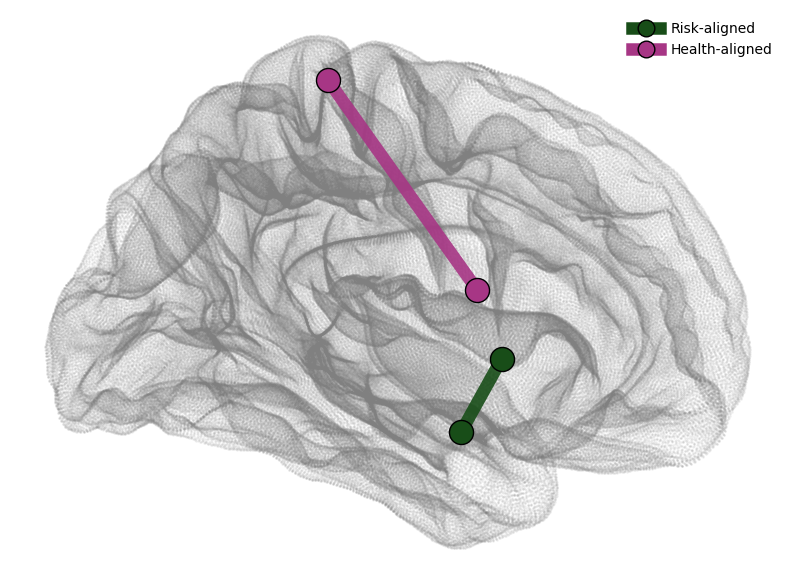

In [8]:
### Figure 3a ###

plot_aligned_edge_example(aligned_overlap_masks['Mental Health & Genetics'],
    matrices=[mental_health_edge_matrix, genetics_LV1_edge_matrix],
    matrix_names=['Mental Health', 'Genetics'],plot_args=plot_args,
    save_name='aligned_M&G_edge_example.pdf',flip=['Genetics'])

M&G Aligned edges: 801 -> keeping top 641 (80%): 281 Risk-aligned, 360 Health-aligned


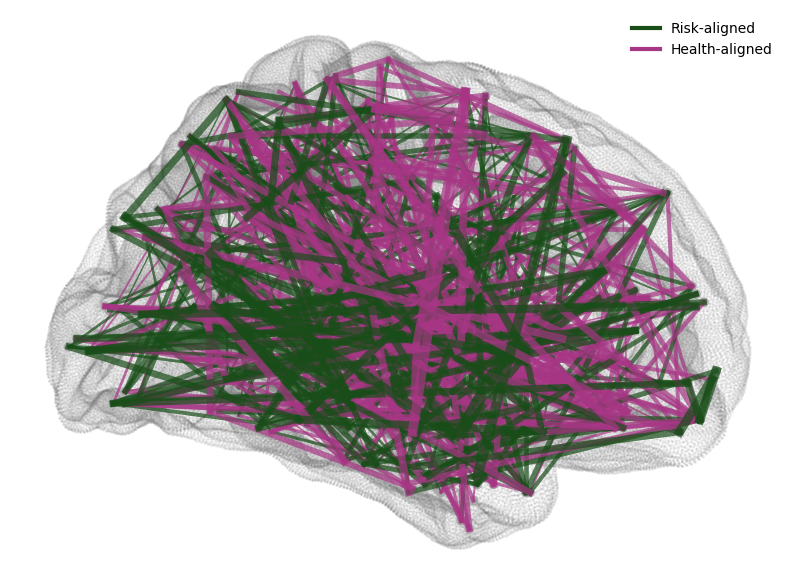

A&G Aligned edges: 777 -> keeping top 622 (80%): 324 Risk-aligned, 298 Health-aligned


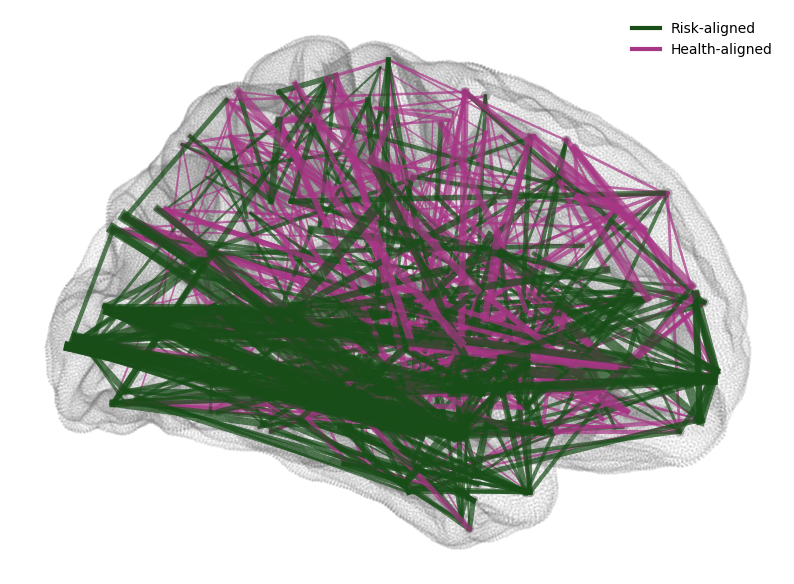

M&A Aligned edges: 1,077 -> keeping top 862 (80%): 335 Risk-aligned, 527 Health-aligned


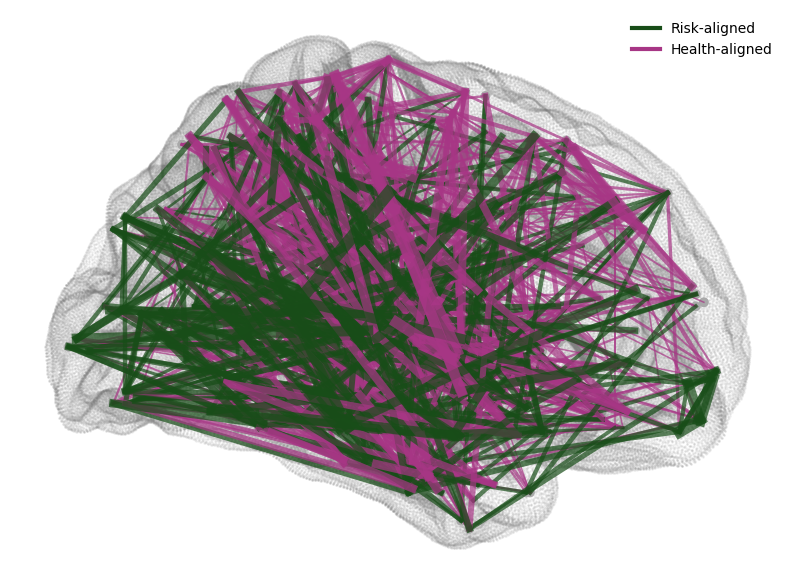

In [9]:
### Figure 3b-d ###

# M&G plot
edge_group_node_plot(aligned_overlap_masks['Mental Health & Genetics'],
                   weight_matrix=mental_health_edge_matrix, plot_args=plot_args,
                   group='M&G', save_name='M&G_node_plot.pdf')

# A&G plot
edge_group_node_plot(aligned_overlap_masks['Adversity & Genetics'],
                   weight_matrix=adversity_edge_matrix, plot_args=plot_args,
                   group='A&G', save_name='A&G_node_plot.pdf')

# M&A plot
edge_group_node_plot(aligned_overlap_masks['Adversity & Mental Health'],
                   weight_matrix=adversity_edge_matrix, plot_args=plot_args,
                   group='M&A', save_name='M&A_node_plot.pdf')
 

In [ ]:
### Calculate participant-level scores per edge group (M&A, A&G and M&G) ###

edge_group_scores, edge_group_details = get_edge_group_scores(connectomes, aligned_overlap_masks)

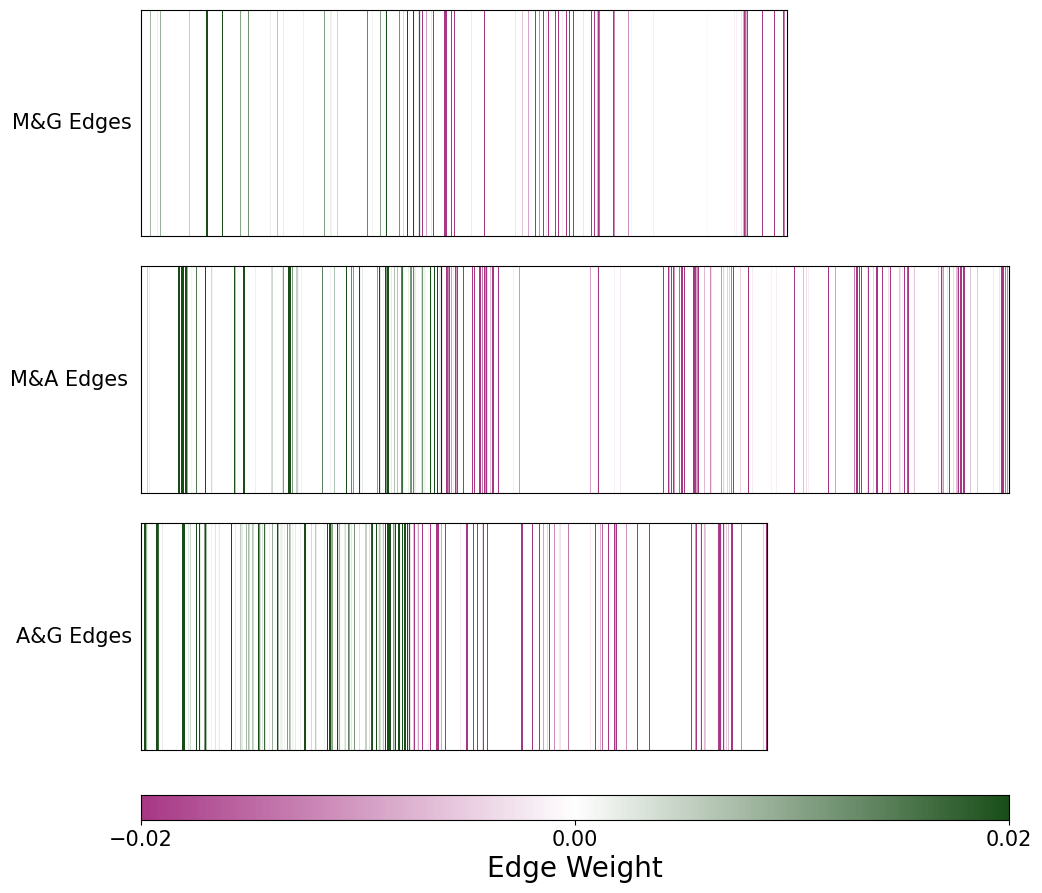

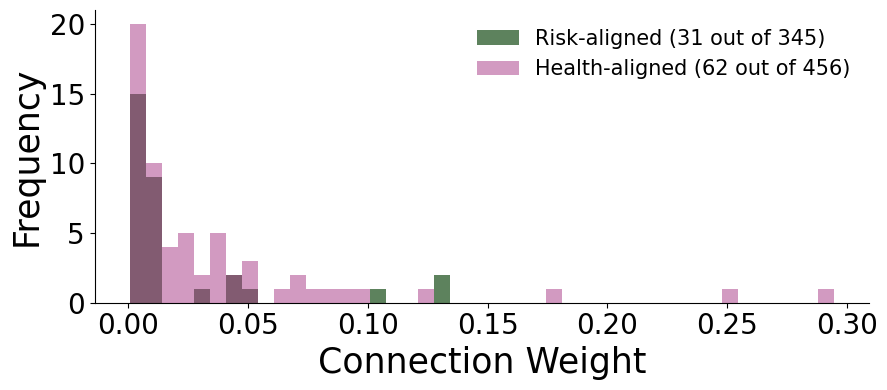

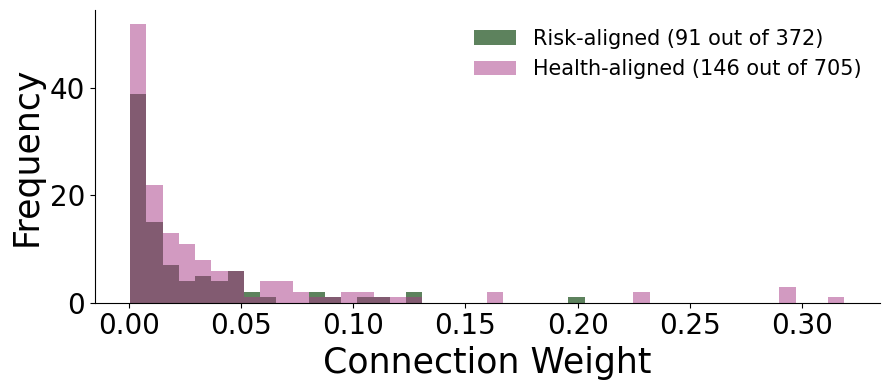

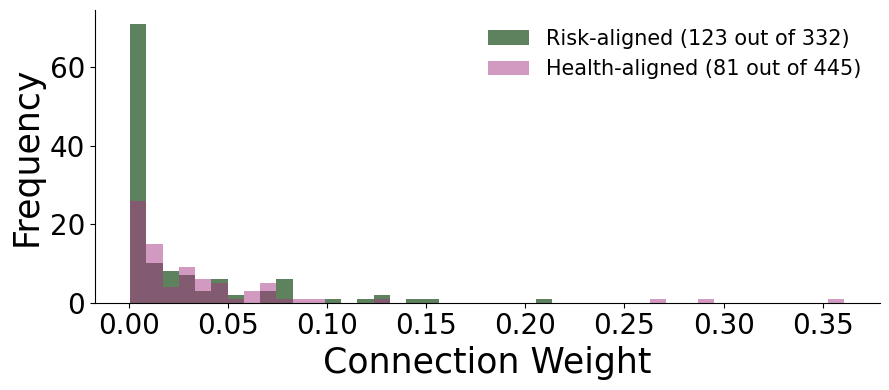

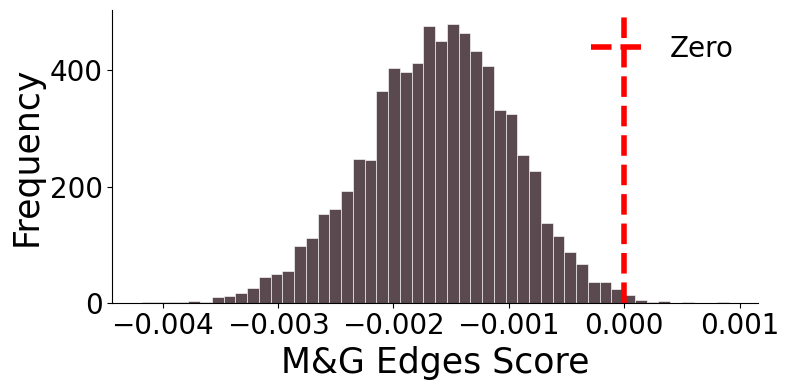

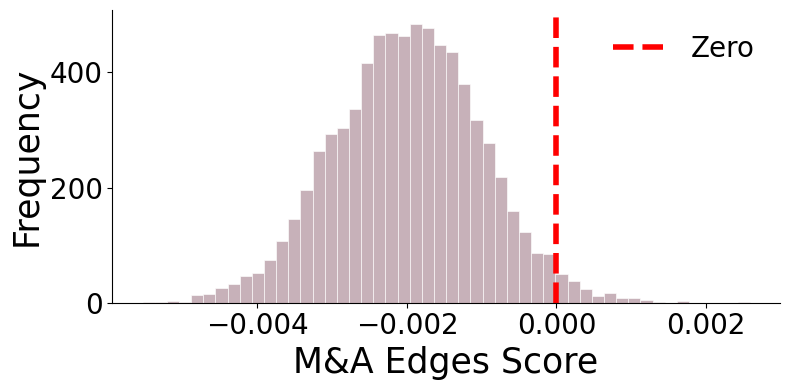

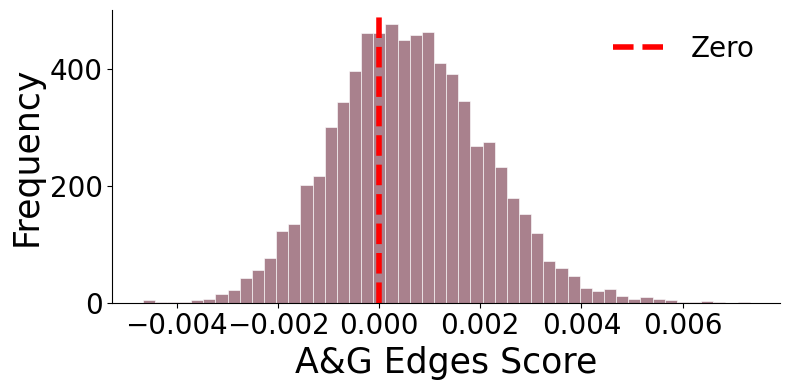

In [17]:
### Figure 3e,f ###

edge_group_plots(connectomes, aligned_overlap_masks, edge_group_scores,save_path=save_dir)